# 03 · Sequence classification

Classify every retained sequence using its configured timing, magnitude, and tree-structure features. A classification describes the algorithmic feature pattern; it does not by itself identify a physical driving mechanism.


Completed classify; inputs and products recorded in regional_notebook_session.json.
Classified sequences: 63
sequence_type
MA       11
Mixed    23
Swarm    29


,file_name,refined_cluster,num,sequence_type,datetime,mag,mag_diff,mean_t,skew,leaf_depth
0,refined_QTM_C10151.0_20090720_M3.6_Direct.csv,0,245,Swarm,2009-07-20 12:10:20.251000+00:00,3.63,0.09,0.682714,3.941129,7.232804
1,refined_QTM_C1051.0_20080309_M4.0_Direct.csv,0,86,MA,2008-03-09 09:22:31.806000+00:00,3.97,0.54,0.052370,6.768240,2.283784
2,refined_QTM_C10839.0_20090818_M2.6_Direct.csv,0,53,Mixed,2009-08-18 01:48:26.672000+00:00,2.64,0.28,0.085097,4.938393,6.633333
3,refined_QTM_C12565.0_20091116_M3.6_Direct.csv,0,85,Mixed,2009-11-16 13:54:33.770000+00:00,3.61,0.71,0.204559,3.089870,4.724638
4,refined_QTM_C13855.0_20100109_M2.6_Direct.csv,0,51,Swarm,2010-01-09 00:07:24.020000+00:00,2.60,0.17,0.896010,4.216646,11.068966
5,refined_QTM_C14600.0_20100213_M4.1_Direct.csv,0,745,Mixed,2010-02-13 21:39:06.276000+00:00,4.10,0.51,0.379385,1.426194,7.889720
6,refined_QTM_C16198.0_20100405_M2.8_Direct.csv,0,53,Mixed,2010-04-05 05:42:18.529000+00:00,2.81,0.06,0.314716,3.699877,5.500000
7,refined_QTM_C17866.0_20100603_M3.2_Direct.csv,0,60,Swarm,2010-06-03 08:44:13.310000+00:00,3.18,0.39,1.143027,1.376487,9.219512
8,refined_QTM_C18100.0_20100613_M4.5_Direct.csv,0,463,Mixed,2010-06-13 03:08:57.139000+00:00,4.45,0.22,0.468717,3.702325,2.497630
9,refined_QTM_C18957.0_20100707_M5.4_Direct.csv,0,2320,MA,2010-07-07 23:53:33.371000+00:00,5.43,2.03,0.001689,87.336736,2.342119


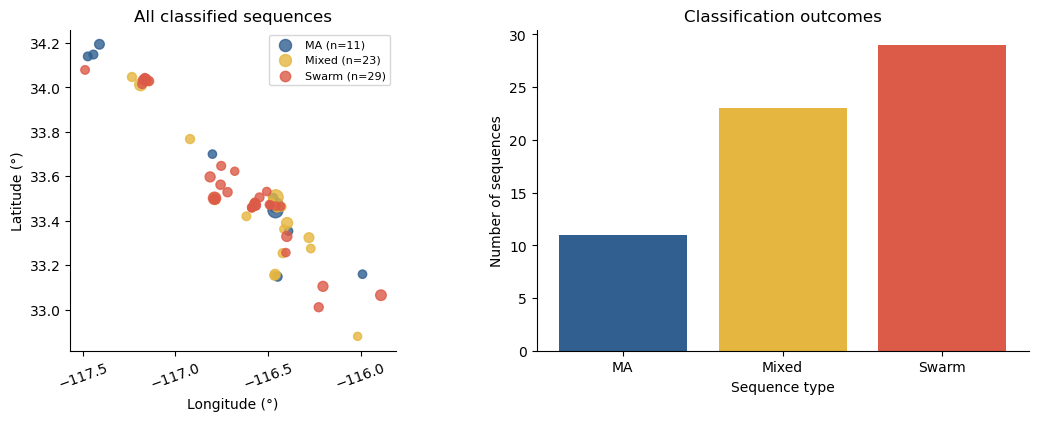

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
root = next((p for p in (here, *here.parents) if (p / "run_aspect.py").is_file()), None)
assert root is not None, "Open the notebook from within the ASPECT repository."
sys.path.insert(0, str(root / "notebooks"))
import regional_utils as w
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

w.run_stage("classify")
classes = pd.read_csv(w.TEXT / "classification_results.csv")
assert len(classes), "No refined sequence passed the classification gate."
counts = classes.sequence_type.value_counts().reindex(["MA", "Mixed", "Swarm"], fill_value=0)
print(f"Classified sequences: {len(classes)}")
print(counts.rename("count").to_string())
columns = ["file_name", "refined_cluster", "num", "sequence_type", "datetime", "mag", "mag_diff", "mean_t", "skew", "leaf_depth"]
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100): display(classes[columns])
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.1), constrained_layout=True)
colors = {"MA":"#315f90", "Mixed":"#e5b640", "Swarm":"#dc5a48"}
for name, group in classes.groupby("sequence_type"):
    ax[0].scatter(group.lon, group.lat, s=20 + 2*np.sqrt(group.num), color=colors[name], label=f"{name} (n={len(group)})", alpha=.8)
ax[0].set(xlabel="Longitude (°)", ylabel="Latitude (°)", title="All classified sequences")
ax[0].set_aspect(1 / np.cos(np.deg2rad(classes.lat.mean())))
ax[0].xaxis.set_major_locator(plt.MaxNLocator(4))
ax[0].tick_params(axis="x", rotation=20)
ax[0].legend(fontsize=8)
ax[1].bar(counts.index, counts.values, color=[colors[k] for k in counts.index])
ax[1].set(xlabel="Sequence type", ylabel="Number of sequences", title="Classification outcomes")
ax[1].yaxis.get_major_locator().set_params(integer=True); plt.show()

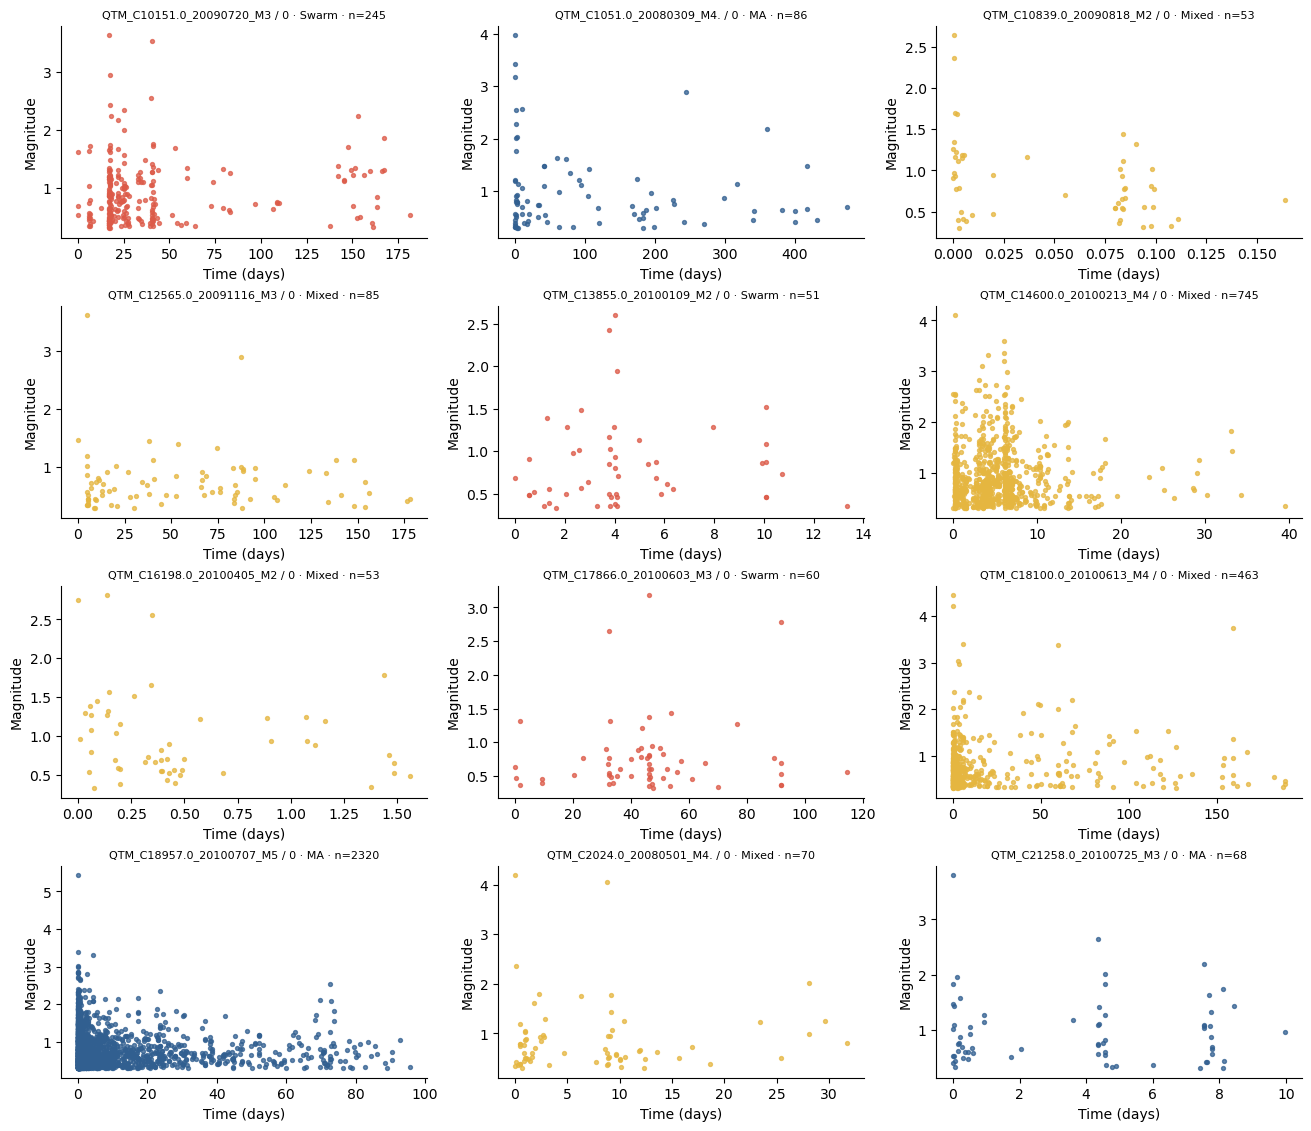

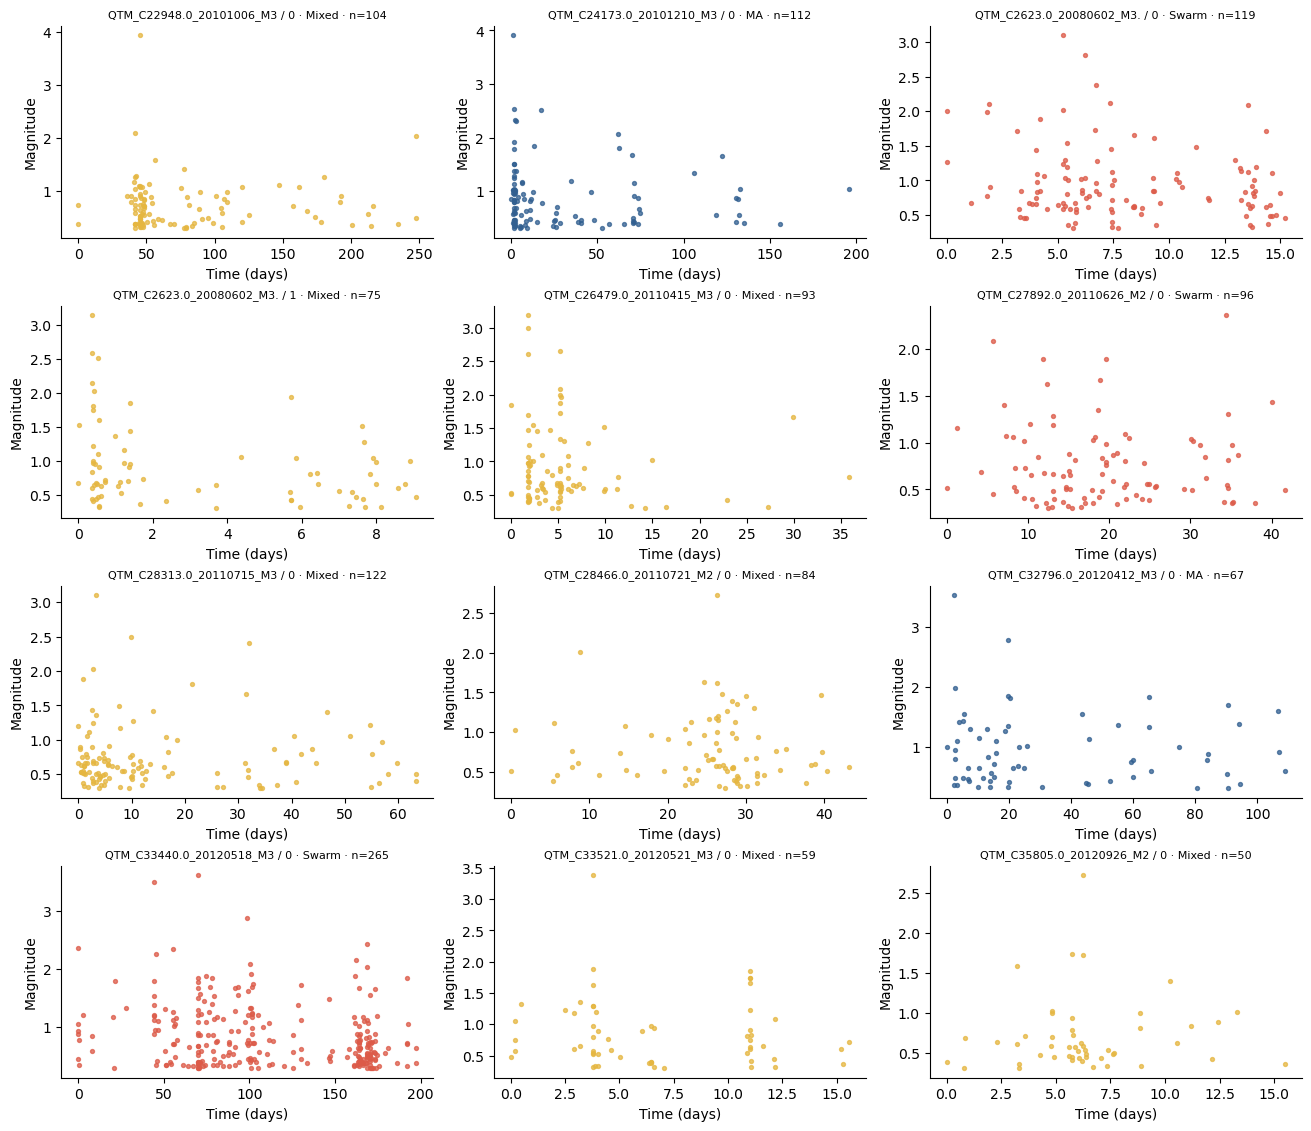

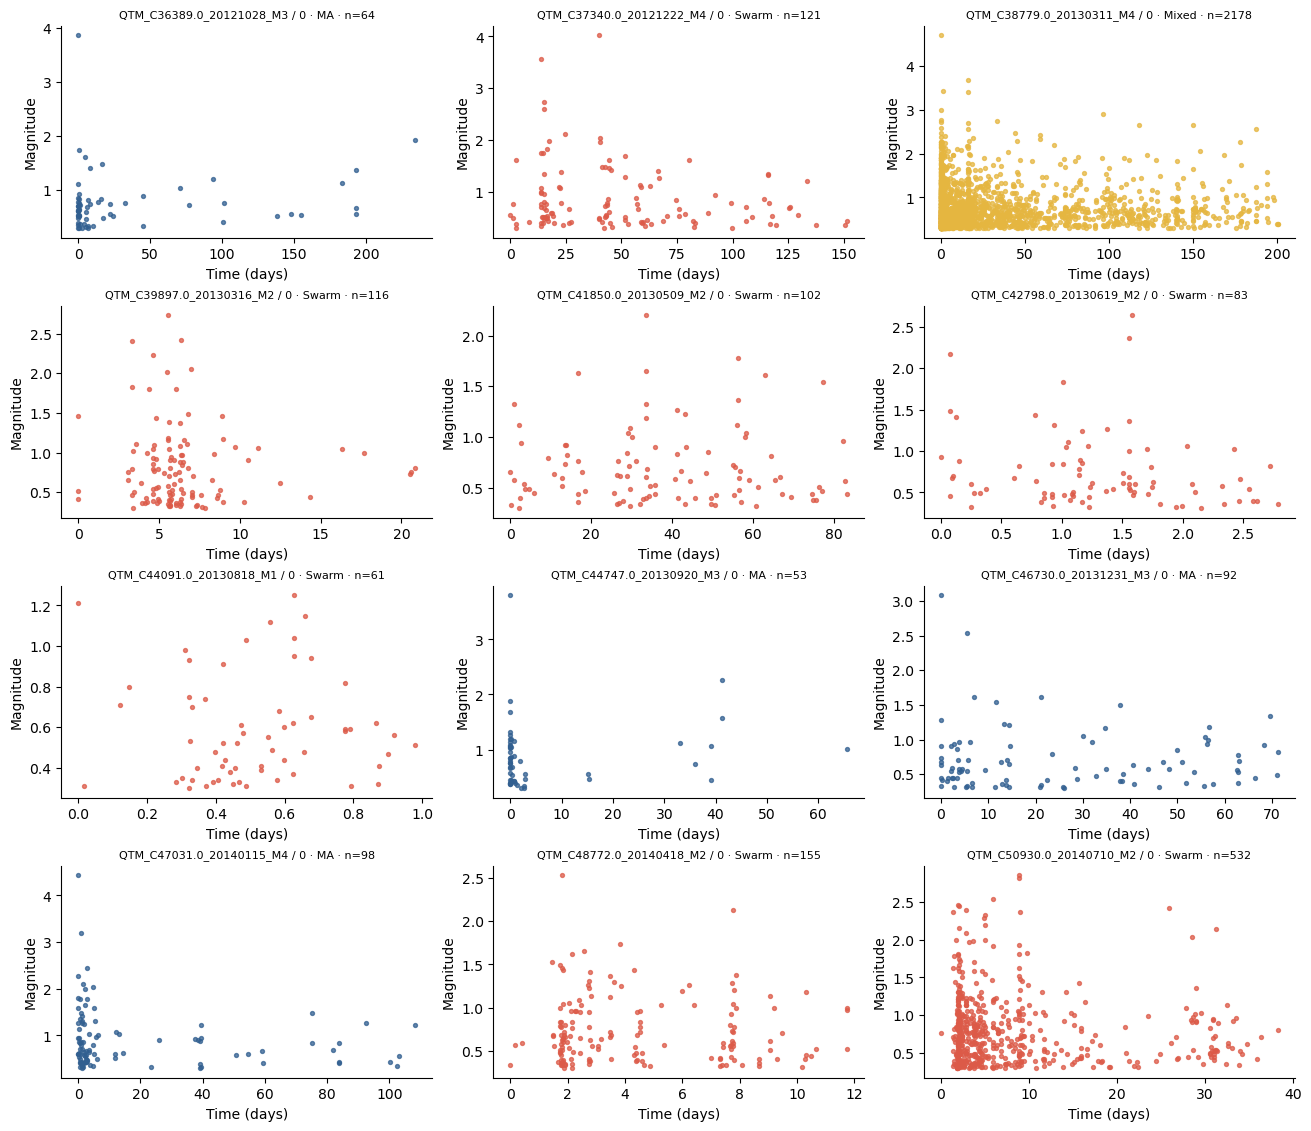

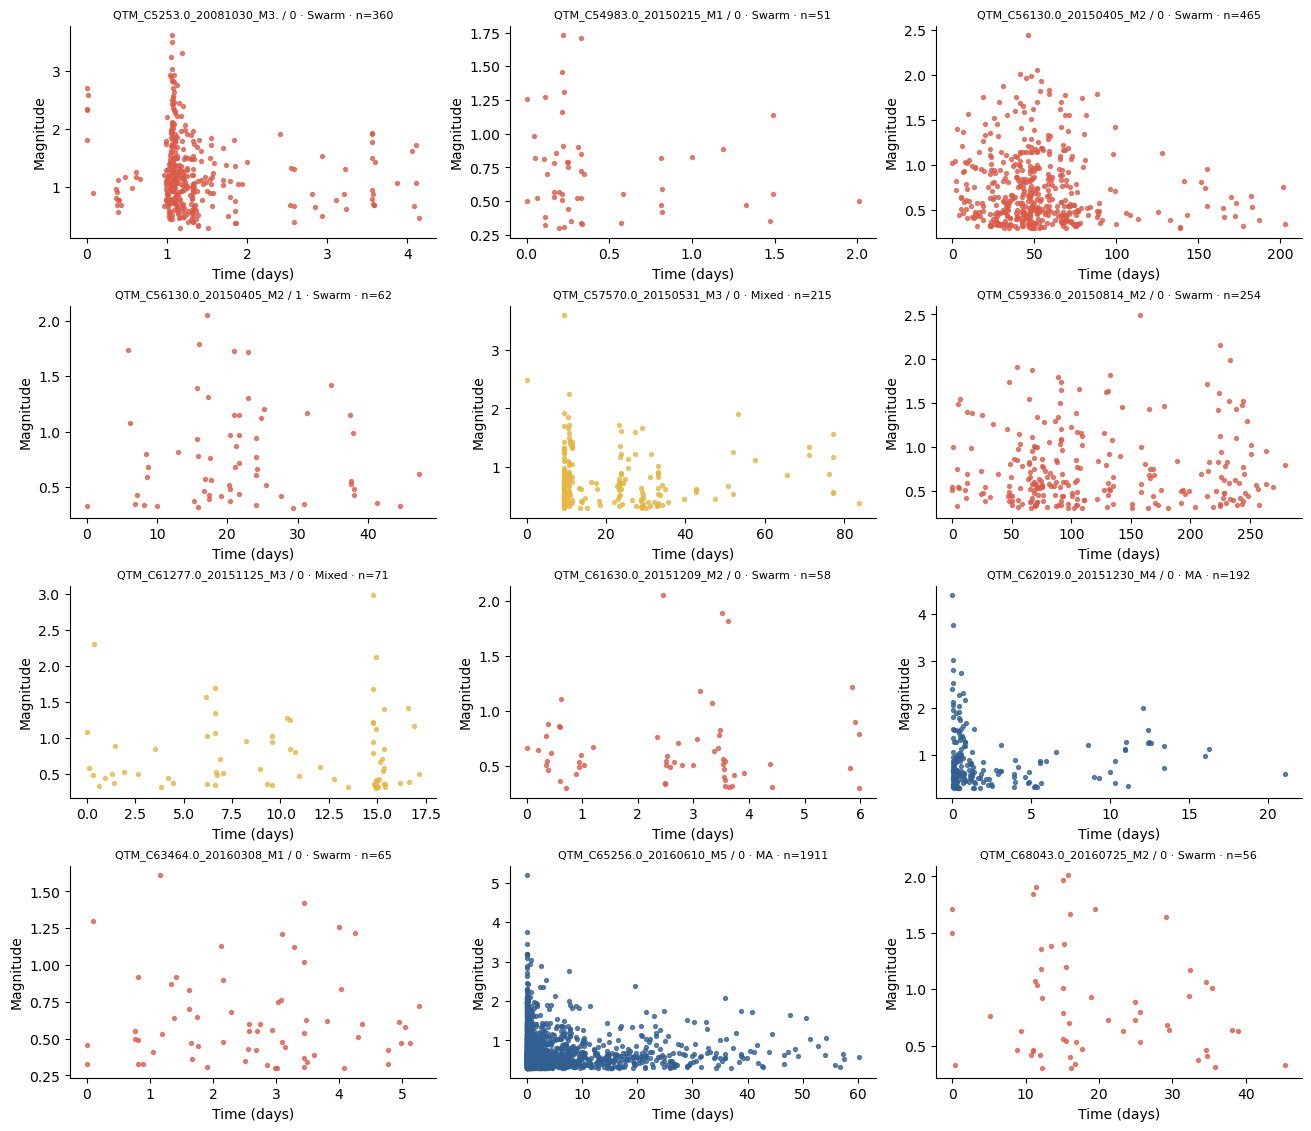

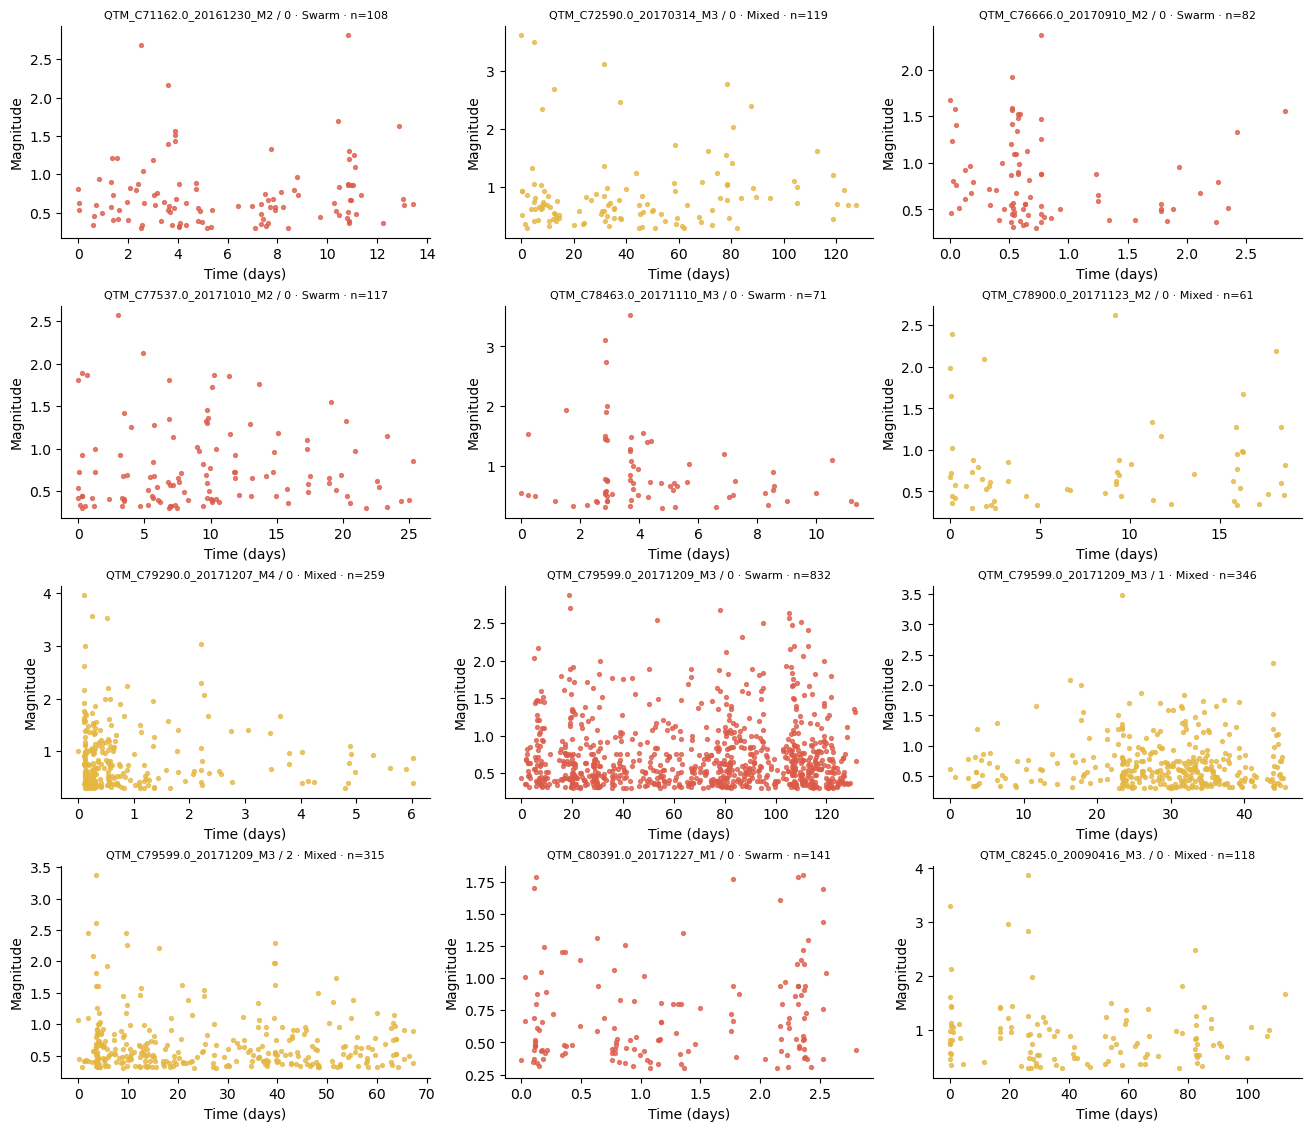

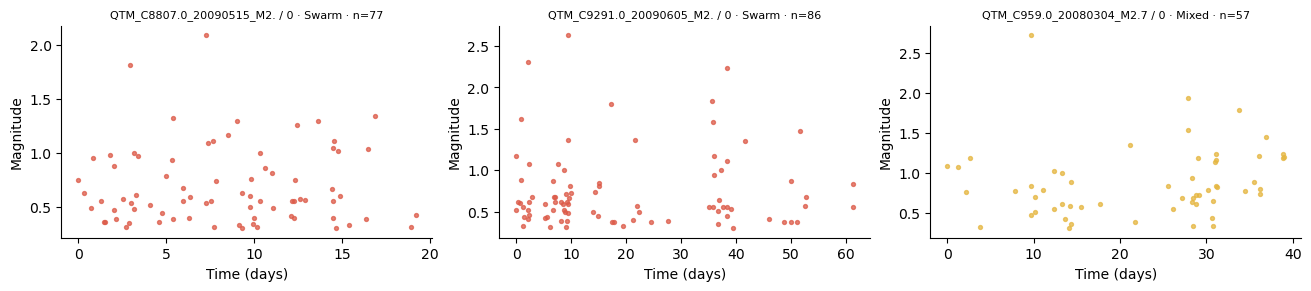

In [2]:
# Plot the magnitude–time distribution of every classified sequence.
for offset in range(0, len(classes), 12):
    page = classes.iloc[offset:offset + 12]
    nrows = int(np.ceil(len(page) / 3))
    fig, axes = plt.subplots(nrows, 3, figsize=(13, 2.8*nrows), squeeze=False, constrained_layout=True)
    for ax, (_, row) in zip(axes.flat, page.iterrows()):
        df = pd.read_csv(w.TEXT / row.file_name)
        df["datetime"] = pd.to_datetime(df["datetime"], format="mixed", utc=True)
        df = df[df.refined_cluster.eq(row.refined_cluster)].sort_values("datetime")
        t = (df.datetime - df.datetime.min()).dt.total_seconds() / 86400
        ax.scatter(t, df.mag, s=8, color=colors[row.sequence_type], alpha=.75)
        ax.set(xlabel="Time (days)", ylabel="Magnitude")
        ax.set_title(f"{row.file_name[8:32]} / {row.refined_cluster} · {row.sequence_type} · n={len(df)}", fontsize=8)
    for ax in axes.flat[len(page):]: ax.axis("off")
    plt.show()

Every classified sequence appears in the table and in one magnitude–time panel. Proceed to `04_migration.ipynb`.